<a href="https://colab.research.google.com/github/kallylxy2026/Team-25/blob/main/Project_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Resources

In [1]:
#import everything
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression


In [2]:
# Download the clean flats file into this notebook (run this once)
import urllib.request
urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1cna7f20L_fTHQjt26rJ3CbkUJj93bRX6", "politifact_fact_check_data.csv")
#print("politifact_fact_check_data.csv")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1LMWrNqhxf4W-3ANuMvsksydcTDH31JMz", "us_life_satisfaction_all_adults.csv")
#print("us_life_satisfaction_all_adults.csv")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1MSTDMRK2GkszvqrFKmb-Da21qyZuXLF9", "life_satisfaction_18to29.xlsx")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1hbVJ1PjITi-m5AjXyBNyq8JBe6LjsRX7", "life_satisfaction_30to44.xlsx")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=12Y5jw9VOpM-4-a_owEQCr4d-Lf_lGwSU", "life_satisfaction_45to64.xlsx")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1KEAKjgFgu5vL_CCcuFJqB30CYvOQkQpp", "life_satisfaction_65to79.xlsx")

('life_satisfaction_65to79.xlsx', <http.client.HTTPMessage at 0x7f11579ec2d0>)

In [3]:
life_satisfaction_18to29 = pd.read_excel("life_satisfaction_18to29.xlsx")
life_satisfaction_30to44 = pd.read_excel("life_satisfaction_30to44.xlsx")
life_satisfaction_45to64 = pd.read_excel("life_satisfaction_45to64.xlsx")
life_satisfaction_65to79 = pd.read_excel("life_satisfaction_65to79.xlsx")

In [4]:
life_satisfaction_18to29.head()

,"Overall, how satisfied are you with your life nowadays?To be answered on a scale of 0 to 10, where 0 is “not at all” and 10 is “completely”.",2020-11-26,2020-12-03,2020-12-10,2020-12-17,2020-12-24,2020-12-31,2021-01-07,2021-01-14,2021-01-21,...,2026-09-09,2026-09-16,2026-09-23,2026-09-30,2026-10-07,2026-10-14,2026-10-21,2026-10-28,2026-11-04,2026-11-11
0,0 - Not at all,0.03,0.05,0.07,0.04,0.06,0.06,0.03,0.05,0.05,...,0.03,0.05,0.06,0.02,0.03,0.03,0.03,0.02,0.06,0.06
1,1,0.03,0.01,0.04,0.04,0.03,0.02,0.02,0.01,0.04,...,0.01,0.01,0.01,0.00,0.03,0.02,0.03,0.01,0.01,0.01
2,2,0.03,0.08,0.03,0.04,0.06,0.05,0.06,0.04,0.06,...,0.04,0.02,0.02,0.06,0.03,0.04,0.04,0.01,0.03,0.03
3,3,0.06,0.10,0.11,0.09,0.08,0.10,0.09,0.10,0.05,...,0.05,0.05,0.05,0.06,0.05,0.06,0.03,0.10,0.08,0.03
4,4,0.12,0.09,0.12,0.09,0.11,0.09,0.09,0.10,0.06,...,0.09,0.06,0.07,0.06,0.10,0.09,0.08,0.10,0.08,0.06


# Misinformation Data

In [5]:
import pandas as pd
from google.colab import data_table

data = pd.read_csv("politifact_fact_check_data.csv")
data.head()

,statement,author,date_stated,source,label,fact_checker,article_url
0,“CBS Evening News” anchor Norah O’Donnell was ...,Threads posts,"January 23, 2025",a Threads post,false,Jeff Cercone,https://www.politifact.com/factchecks/2025/jan...
1,The U.S. House Select Committee that investiga...,Donald Trump,"January 22, 2025",an interview,false,Samantha Putterman,https://www.politifact.com/factchecks/2025/jan...
2,"Video muestra a inmigrantes en México que ""se ...",X posts,"January 21, 2025",una publicación en X,false,Marta Campabadal Graus,https://www.politifact.com/factchecks/2025/jan...
3,“Fani Willis has just confessed to collusion w...,Instagram posts,"January 22, 2025",an Instagram post,false,Sofia Ahmed,https://www.politifact.com/factchecks/2025/jan...
4,Image shows President Donald Trump responding ...,Viral image,"January 20, 2025",a Facebook post,false,Ciara O'Rourke,https://www.politifact.com/factchecks/2025/jan...


In [6]:
# Rename "barely-true" to "mostly-false"

data["label"] = data["label"].replace("barely-true", "mostly-false")

In [7]:
# Delete "half-flip" and "full-flop" from the original dataset

data_cleaning = data[
    ~data["label"].isin(["half-flip", "full-flop"])
].copy()

In [8]:
# recoding the variable labels using integers
# test run: filter the dataframe using false

false_only = data_cleaning[data_cleaning["label"] == "false"]
#false_only.head(20)

# add a new column with the score 2
false_only["score"] = 2

#false_only.head(20)

# repeat for pants-fire (score 1)

pantsfire_only = data_cleaning[data_cleaning["label"] == "pants-fire"]
pantsfire_only["score"] = 1

# repeat for mostly-false (score 3)
mostlyfalse_only = data_cleaning[data_cleaning["label"] == "mostly-false"]
mostlyfalse_only["score"] = 3

# repeat for half-true (score 4)
halftrue_only = data_cleaning[data_cleaning["label"] == "half-true"]
halftrue_only["score"] = 4

# repeat for mostly-true (score 5)
mostlytrue_only = data_cleaning[data_cleaning["label"] == "mostly-true"]
mostlytrue_only["score"] = 5

# repeat for mostly-true (score 5)
true_only = data_cleaning[data_cleaning["label"] == "true"]
true_only["score"] = 6

/tmp/ipykernel_1446/1502158021.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  false_only["score"] = 2
/tmp/ipykernel_1446/1502158021.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pantsfire_only["score"] = 1
/tmp/ipykernel_1446/1502158021.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.htm

In [9]:
# vertically concatenate the subset dataframes together

data_recoded = pd.concat([false_only, pantsfire_only, mostlyfalse_only, halftrue_only, mostlytrue_only, true_only])
data_recoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2512 entries, 0 to 2510
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   statement     2512 non-null   object
 1   author        2512 non-null   object
 2   date_stated   2512 non-null   object
 3   source        2512 non-null   object
 4   label         2512 non-null   object
 5   fact_checker  2512 non-null   object
 6   article_url   2512 non-null   object
 7   score         2512 non-null   int64 
dtypes: int64(1), object(7)
memory usage: 176.6+ KB


In [10]:
# check the shape of the data
data_recoded.head()

,statement,author,date_stated,source,label,fact_checker,article_url,score
0,“CBS Evening News” anchor Norah O’Donnell was ...,Threads posts,"January 23, 2025",a Threads post,false,Jeff Cercone,https://www.politifact.com/factchecks/2025/jan...,2
1,The U.S. House Select Committee that investiga...,Donald Trump,"January 22, 2025",an interview,false,Samantha Putterman,https://www.politifact.com/factchecks/2025/jan...,2
2,"Video muestra a inmigrantes en México que ""se ...",X posts,"January 21, 2025",una publicación en X,false,Marta Campabadal Graus,https://www.politifact.com/factchecks/2025/jan...,2
3,“Fani Willis has just confessed to collusion w...,Instagram posts,"January 22, 2025",an Instagram post,false,Sofia Ahmed,https://www.politifact.com/factchecks/2025/jan...,2
4,Image shows President Donald Trump responding ...,Viral image,"January 20, 2025",a Facebook post,false,Ciara O'Rourke,https://www.politifact.com/factchecks/2025/jan...,2


# Life satisfaction data

In [11]:
import pandas as pd

life_satisfaction = pd.read_csv("us_life_satisfaction_all_adults.csv")

In [12]:
life_satisfaction.shape

(14, 312)

In [13]:
life_satisfaction.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Columns: 312 entries, Overall, how satisfied are you with your life nowadays?To be answered on a scale of 0 to 10, where 0 is “not at all” and 10 is “completely”. to 2026-11-11
dtypes: object(312)
memory usage: 34.3+ KB


In [14]:
life_satisfaction.describe()

,"Overall, how satisfied are you with your life nowadays?To be answered on a scale of 0 to 10, where 0 is “not at all” and 10 is “completely”.",2020-11-26,2020-12-03,2020-12-10,2020-12-17,2020-12-24,2020-12-31,2021-01-07,2021-01-14,2021-01-21,...,2026-09-09,2026-09-16,2026-09-23,2026-09-30,2026-10-07,2026-10-14,2026-10-21,2026-10-28,2026-11-04,2026-11-11
count,14,14,14,14,14,14,14,14,14,14,...,14,14,14,14,14,14,14,14,14,14
unique,14,10,9,10,10,9,10,12,11,8,...,9,10,10,10,11,10,11,12,12,11
top,0 - Not at all,3%,3%,4%,3%,5%,5%,7%,1031,7%,...,3%,2%,2%,2%,7%,4%,3%,2%,1001,5%
freq,1,2,2,3,3,2,2,2,2,3,...,2,2,2,2,3,2,2,2,2,2


In [15]:
life_satisfaction.head()

,"Overall, how satisfied are you with your life nowadays?To be answered on a scale of 0 to 10, where 0 is “not at all” and 10 is “completely”.",2020-11-26,2020-12-03,2020-12-10,2020-12-17,2020-12-24,2020-12-31,2021-01-07,2021-01-14,2021-01-21,...,2026-09-09,2026-09-16,2026-09-23,2026-09-30,2026-10-07,2026-10-14,2026-10-21,2026-10-28,2026-11-04,2026-11-11
0,0 - Not at all,5%,3%,4%,3%,5%,5%,4%,5%,4%,...,4%,4%,5%,3%,5%,4%,3%,3%,6%,5%
1,1,3%,2%,2%,3%,2%,2%,2%,2%,3%,...,2%,2%,2%,2%,2%,1%,2%,2%,1%,1%
2,2,4%,7%,4%,3%,5%,5%,5%,4%,4%,...,3%,3%,4%,4%,4%,4%,3%,4%,4%,4%
3,3,6%,7%,8%,8%,7%,7%,7%,8%,6%,...,6%,6%,6%,7%,7%,6%,6%,8%,7%,5%
4,4,9%,6%,8%,7%,8%,7%,7%,7%,7%,...,8%,6%,7%,7%,7%,7%,7%,6%,8%,8%


In [16]:
life_satisfaction.isna().sum()

,0
"Overall, how satisfied are you with your life nowadays?To be answered on a scale of 0 to 10, where 0 is “not at all” and 10 is “completely”.",0
2020-11-26,0
2020-12-03,0
2020-12-10,0
2020-12-17,0
...,...
2026-10-14,0
2026-10-21,0
2026-10-28,0
2026-11-04,0


In [17]:
# check for all alternatives
life_satisfaction_18to29.isna().sum()


,0
"Overall, how satisfied are you with your life nowadays?To be answered on a scale of 0 to 10, where 0 is “not at all” and 10 is “completely”.",0
2020-11-26,0
2020-12-03,0
2020-12-10,0
2020-12-17,0
...,...
2026-10-14,0
2026-10-21,0
2026-10-28,0
2026-11-04,0


In [18]:
life_satisfaction_30to44.isna().sum()


,0
"Overall, how satisfied are you with your life nowadays?To be answered on a scale of 0 to 10, where 0 is “not at all” and 10 is “completely”.",0
2020-11-26,0
2020-12-03,0
2020-12-10,0
2020-12-17,0
...,...
2026-10-14,0
2026-10-21,0
2026-10-28,0
2026-11-04,0


In [19]:
life_satisfaction_45to64.isna().sum()


,0
"Overall, how satisfied are you with your life nowadays?To be answered on a scale of 0 to 10, where 0 is “not at all” and 10 is “completely”.",0
2020-11-26,0
2020-12-03,0
2020-12-10,0
2020-12-17,0
...,...
2026-10-14,0
2026-10-21,0
2026-10-28,0
2026-11-04,0


In [20]:
life_satisfaction_65to79.isna().sum()

,0
"Overall, how satisfied are you with your life nowadays?To be answered on a scale of 0 to 10, where 0 is “not at all” and 10 is “completely”.",0
2020-11-26,0
2020-12-03,0
2020-12-10,0
2020-12-17,0
...,...
2026-10-14,0
2026-10-21,0
2026-10-28,0
2026-11-04,0


# Coverting the date

In [21]:
data_recoded["date_formatted"] = pd.to_datetime(
    data_recoded["date_stated"], format="%B %d, %Y"
).dt.strftime("%Y-%m-%d")
print(data_recoded["date_stated"].head())

0    January 23, 2025
1    January 22, 2025
2    January 21, 2025
3    January 22, 2025
4    January 20, 2025
Name: date_stated, dtype: object


# Joining the datasets

In [22]:
# Monthly misinformation percentage

politifact = data_recoded.copy()

politifact["date_stated"] = pd.to_datetime(
    politifact["date_stated"], format="mixed"
)

politifact["month"] = politifact["date_stated"].dt.to_period("M")
politifact["is_false"] = politifact["score"].isin([1, 2, 3])

politifact_monthly = politifact.groupby("month")["is_false"].agg(
    ["size", "mean"]
)

politifact_monthly.columns = ["n_checked", "false_percentage"]
politifact_monthly["false_percentage"] *= 100
politifact_monthly = politifact_monthly.reset_index()


# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfaction = life_satisfaction.iloc[:11, 1:].T.copy()
satisfaction.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfaction[score] = (
        satisfaction[score].str.rstrip("%").astype(float)
    )

# Calculate the average score, excluding "Don't know"
total_percentage = satisfaction.sum(axis=1)
weighted_total = 0

for score in range(11):
    weighted_total += score * satisfaction[score]

satisfaction["life_satisfaction"] = weighted_total / total_percentage


# Monthly life satisfaction

satisfaction["month"] = pd.to_datetime(
    satisfaction.index
).to_period("M")

life_monthly = satisfaction.groupby("month")["life_satisfaction"].agg(
    ["mean", "size"]
)

life_monthly.columns = ["life_satisfaction", "n_surveys"]
life_monthly = life_monthly.reset_index()


# Merge data

merged_data = pd.merge(
    politifact_monthly,
    life_monthly,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_data = merged_data[
    (merged_data["month"] >= "2023-10")
    & (merged_data["month"] <= "2026-03")
]

merged_data = merged_data.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_data))
print("Missing values:")
print(merged_data.isna().sum())

display(merged_data)

Number of months: 30
Missing values:
month                0
n_checked            0
false_percentage     0
life_satisfaction    0
n_surveys            0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction,n_surveys
0,2023-10,4,100.000000,6.224733,4
1,2023-11,50,84.000000,6.248342,5
2,2023-12,68,86.764706,6.255102,4
3,2024-01,119,88.235294,6.266378,4
4,2024-02,111,85.585586,6.320163,5
5,2024-03,155,85.806452,6.342157,4
6,2024-04,130,93.076923,6.254677,4
7,2024-05,133,90.225564,6.257827,5
8,2024-06,112,93.750000,6.198155,4
9,2024-07,143,91.608392,6.115059,4


In [23]:
# Filtered data ages 18 to 29
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfaction18to29 = life_satisfaction_18to29.iloc[:11, 1:].T.copy()
satisfaction18to29.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfaction18to29[score] = (
        satisfaction18to29[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentage18to29 = satisfaction18to29.sum(axis=1)
weighted_total18to29 = 0

for score in range(11):
    weighted_total18to29 += score * satisfaction18to29[score]

satisfaction18to29["life_satisfaction_18to29"] = weighted_total18to29 / total_percentage18to29


# Monthly life satisfaction

satisfaction18to29["month"] = pd.to_datetime(
    satisfaction18to29.index
).to_period("M")

life_monthly18to29 = satisfaction18to29.groupby("month")["life_satisfaction_18to29"].agg(
    ["mean", "size"]
)

life_monthly18to29.columns = ["life_satisfaction_18to29", "n_surveys"]
life_monthly18to29 = life_monthly18to29.reset_index()


# Merge data

merged_data18to29 = pd.merge(
    politifact_monthly,
    life_monthly18to29,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_data18to29 = merged_data18to29[
    (merged_data18to29["month"] >= "2023-10")
    & (merged_data18to29["month"] <= "2026-03")
]

merged_data18to29 = merged_data18to29.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_data18to29))
print("Missing values:")
print(merged_data18to29.isna().sum())

display(merged_data18to29)

Number of months: 30
Missing values:
month                       0
n_checked                   0
false_percentage            0
life_satisfaction_18to29    0
n_surveys                   0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_18to29,n_surveys
0,2023-10,4,100.000000,5.935601,4
1,2023-11,50,84.000000,5.954897,5
2,2023-12,68,86.764706,6.192979,4
3,2024-01,119,88.235294,6.207595,4
4,2024-02,111,85.585586,6.234471,5
5,2024-03,155,85.806452,6.270895,4
6,2024-04,130,93.076923,6.347170,4
7,2024-05,133,90.225564,6.090795,5
8,2024-06,112,93.750000,5.907723,4
9,2024-07,143,91.608392,5.734095,4


In [24]:
# Filtered data by age processing
# Ages 30 to 44
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfaction30to44 = life_satisfaction_30to44.iloc[:11, 1:].T.copy()
satisfaction30to44.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfaction30to44[score] = (
        satisfaction30to44[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentage30to44 = satisfaction30to44.sum(axis=1)
weighted_total30to44 = 0

for score in range(11):
    weighted_total30to44 += score * satisfaction30to44[score]

satisfaction30to44["life_satisfaction_30to44"] = weighted_total30to44 / total_percentage30to44


# Monthly life satisfaction

satisfaction30to44["month"] = pd.to_datetime(
    satisfaction30to44.index
).to_period("M")

life_monthly30to44 = satisfaction30to44.groupby("month")["life_satisfaction_30to44"].agg(
    ["mean", "size"]
)

life_monthly30to44.columns = ["life_satisfaction_30to44", "n_surveys"]
life_monthly30to44 = life_monthly30to44.reset_index()


# Merge data

merged_data30to44 = pd.merge(
    politifact_monthly,
    life_monthly30to44,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_data30to44 = merged_data30to44[
    (merged_data30to44["month"] >= "2023-10")
    & (merged_data30to44["month"] <= "2026-03")
]

merged_data30to44 = merged_data30to44.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_data30to44))
print("Missing values:")
print(merged_data30to44.isna().sum())

display(merged_data30to44)

Number of months: 30
Missing values:
month                       0
n_checked                   0
false_percentage            0
life_satisfaction_30to44    0
n_surveys                   0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_30to44,n_surveys
0,2023-10,4,100.000000,6.205104,4
1,2023-11,50,84.000000,5.988193,5
2,2023-12,68,86.764706,6.116961,4
3,2024-01,119,88.235294,6.263486,4
4,2024-02,111,85.585586,6.153674,5
5,2024-03,155,85.806452,6.346137,4
6,2024-04,130,93.076923,6.159217,4
7,2024-05,133,90.225564,6.251713,5
8,2024-06,112,93.750000,6.025646,4
9,2024-07,143,91.608392,6.029018,4


In [25]:
# Filtered data by age processing
# Ages 45 to 64
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfaction45to64 = life_satisfaction_45to64.iloc[:11, 1:].T.copy()
satisfaction45to64.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfaction45to64[score] = (
        satisfaction45to64[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentage45to64 = satisfaction45to64.sum(axis=1)
weighted_total45to64 = 0


for score in range(11):
    weighted_total45to64 += score * satisfaction45to64[score]

satisfaction45to64["life_satisfaction_45to64"] = weighted_total45to64 / total_percentage45to64


# Monthly life satisfaction

satisfaction45to64["month"] = pd.to_datetime(
    satisfaction45to64.index
).to_period("M")

life_monthly45to64 = satisfaction45to64.groupby("month")["life_satisfaction_45to64"].agg(
    ["mean", "size"]
)

life_monthly45to64.columns = ["life_satisfaction_45to64", "n_surveys"]
life_monthly45to64 = life_monthly45to64.reset_index()


# Merge data

merged_data45to64 = pd.merge(
    politifact_monthly,
    life_monthly45to64,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_data45to64 = merged_data45to64[
    (merged_data45to64["month"] >= "2023-10")
    & (merged_data45to64["month"] <= "2026-03")
]

merged_data45to64 = merged_data45to64.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_data45to64))
print("Missing values:")
print(merged_data45to64.isna().sum())

display(merged_data45to64)

Number of months: 30
Missing values:
month                       0
n_checked                   0
false_percentage            0
life_satisfaction_45to64    0
n_surveys                   0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_45to64,n_surveys
0,2023-10,4,100.000000,6.224733,4
1,2023-11,50,84.000000,6.248342,5
2,2023-12,68,86.764706,6.255102,4
3,2024-01,119,88.235294,6.266378,4
4,2024-02,111,85.585586,6.320163,5
5,2024-03,155,85.806452,6.342157,4
6,2024-04,130,93.076923,6.254677,4
7,2024-05,133,90.225564,6.257827,5
8,2024-06,112,93.750000,6.198155,4
9,2024-07,143,91.608392,6.115059,4


In [26]:
# Filtered data by age processing
# Ages 65 to 79
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfaction65to79 = life_satisfaction_65to79.iloc[:11, 1:].T.copy()
satisfaction65to79.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfaction65to79[score] = (
        satisfaction65to79[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentage65to79 = satisfaction65to79.sum(axis=1)
weighted_total65to79 = 0


for score in range(11):
    weighted_total65to79 += score * satisfaction65to79[score]

satisfaction65to79["life_satisfaction_65to79"] = weighted_total65to79 / total_percentage65to79


# Monthly life satisfaction

satisfaction65to79["month"] = pd.to_datetime(
    satisfaction65to79.index
).to_period("M")

life_monthly65to79 = satisfaction65to79.groupby("month")["life_satisfaction_65to79"].agg(
    ["mean", "size"]
)

life_monthly65to79.columns = ["life_satisfaction_65to79", "n_surveys"]
life_monthly65to79 = life_monthly65to79.reset_index()


# Merge data

merged_data65to79 = pd.merge(
    politifact_monthly,
    life_monthly65to79,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_data65to79 = merged_data65to79[
    (merged_data65to79["month"] >= "2023-10")
    & (merged_data65to79["month"] <= "2026-03")
]

merged_data65to79 = merged_data65to79.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_data65to79))
print("Missing values:")
print(merged_data65to79.isna().sum())

display(merged_data65to79)

Number of months: 30
Missing values:
month                       0
n_checked                   0
false_percentage            0
life_satisfaction_65to79    0
n_surveys                   0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_65to79,n_surveys
0,2023-10,4,100.000000,5.966547,4
1,2023-11,50,84.000000,6.188495,5
2,2023-12,68,86.764706,5.970144,4
3,2024-01,119,88.235294,6.109672,4
4,2024-02,111,85.585586,6.106065,5
5,2024-03,155,85.806452,6.067528,4
6,2024-04,130,93.076923,5.962851,4
7,2024-05,133,90.225564,5.948061,5
8,2024-06,112,93.750000,6.141174,4
9,2024-07,143,91.608392,6.086345,4


# Data visualization

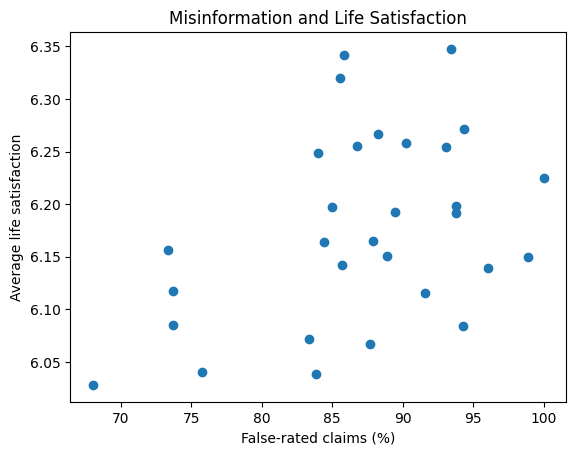

In [27]:
import matplotlib.pyplot as plt

plt.scatter(
    merged_data["false_percentage"],
    merged_data["life_satisfaction"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Misinformation and Life Satisfaction")

plt.show()

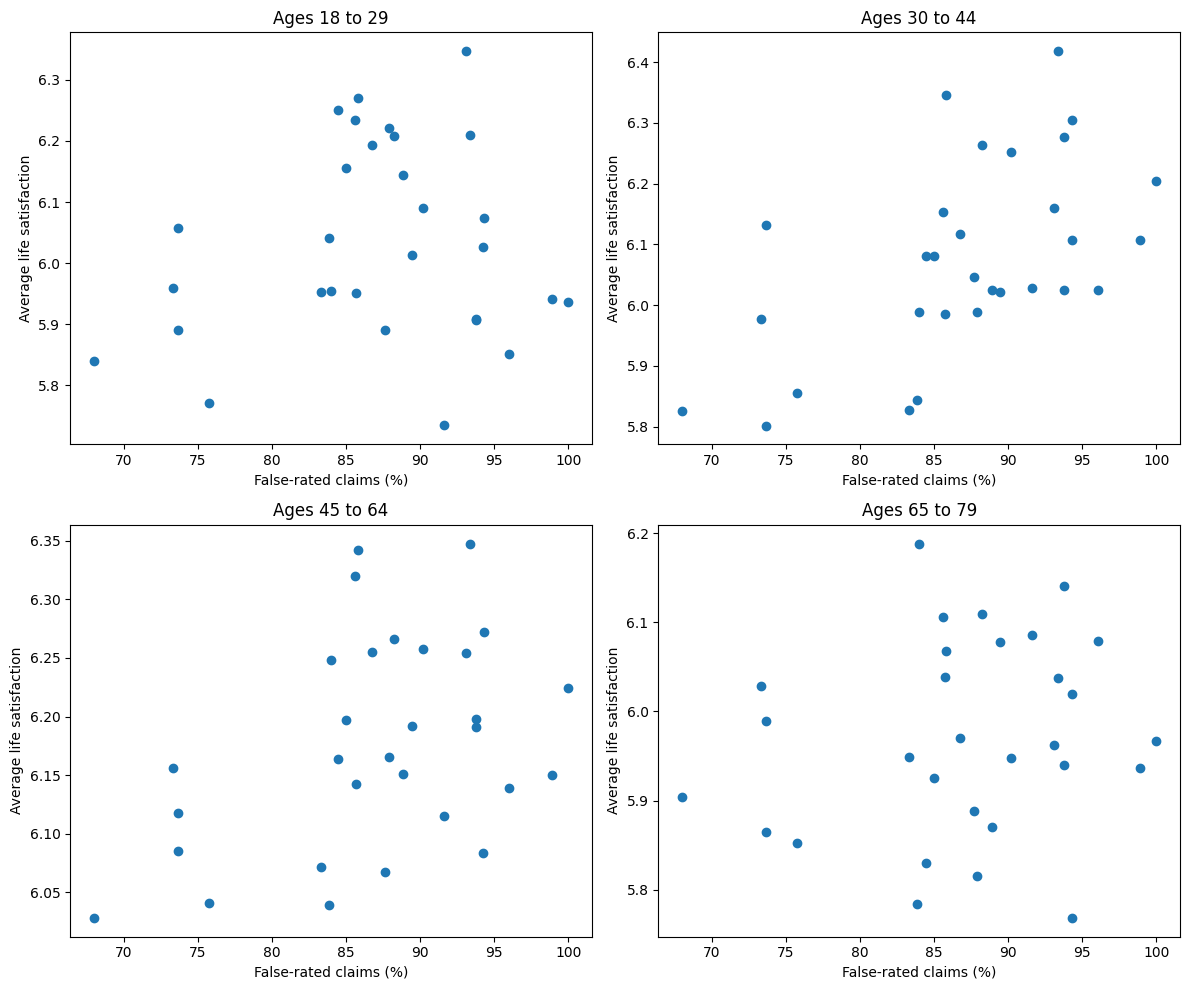

In [28]:
# Plot of life satisfaction against false-rated claims percentage by age group
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

plt.subplot(2,2,1)
plt.scatter(
    merged_data18to29["false_percentage"],
    merged_data18to29["life_satisfaction_18to29"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Ages 18 to 29")



plt.subplot(2,2,2)
plt.scatter(
    merged_data30to44["false_percentage"],
    merged_data30to44["life_satisfaction_30to44"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Ages 30 to 44")



plt.subplot(2,2,3)
plt.scatter(
    merged_data45to64["false_percentage"],
    merged_data45to64["life_satisfaction_45to64"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Ages 45 to 64")



plt.subplot(2,2,4)
plt.scatter(
    merged_data65to79["false_percentage"],
    merged_data65to79["life_satisfaction_65to79"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Ages 65 to 79")

plt.tight_layout()
plt.show()

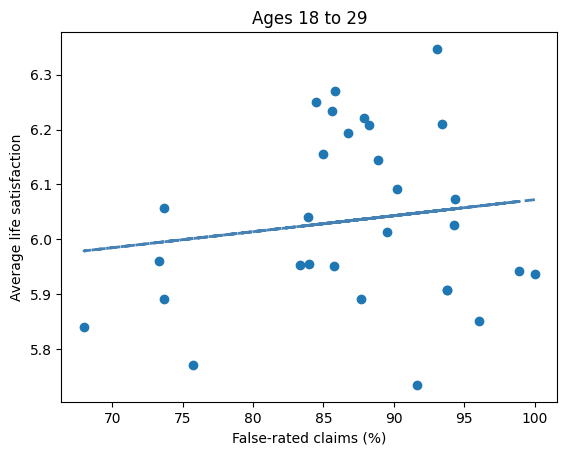

In [29]:
# trying to apply a best fit line

# ages 18 to 29
x = merged_data18to29["false_percentage"]
y = merged_data18to29["life_satisfaction_18to29"]

a, b = np.polyfit(x, y, 1)

plt.scatter(
    merged_data18to29["false_percentage"],
    merged_data18to29["life_satisfaction_18to29"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Ages 18 to 29")

plt.plot(x, a*x+b, color='steelblue', linestyle='--', linewidth=2)






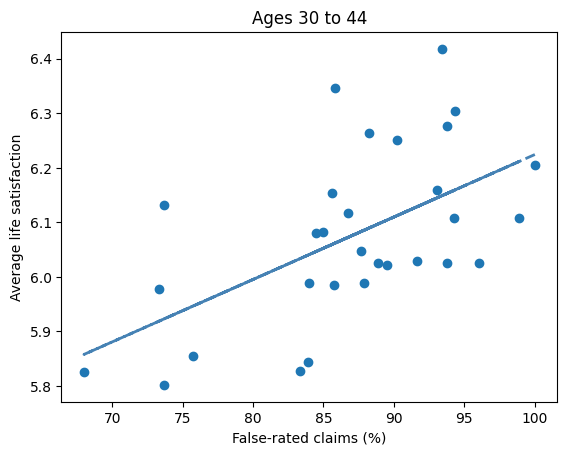

In [30]:
# ages 30 to 44
x = merged_data30to44["false_percentage"]
y = merged_data30to44["life_satisfaction_30to44"]

a, b = np.polyfit(x, y, 1)

plt.scatter(
    merged_data30to44["false_percentage"],
    merged_data30to44["life_satisfaction_30to44"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Ages 30 to 44")

plt.plot(x, a*x+b, color='steelblue', linestyle='--', linewidth=2)







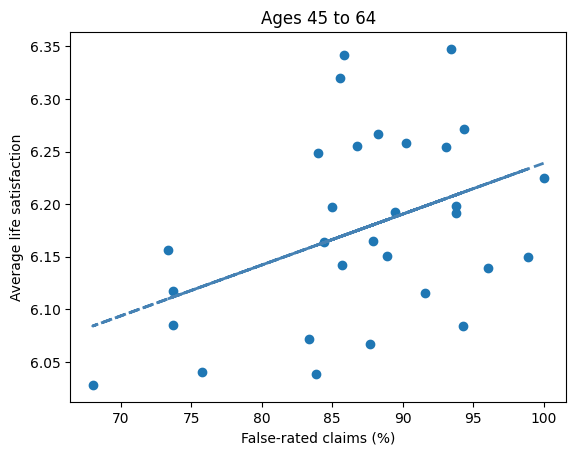

In [31]:
# ages 45 to 64

x = merged_data45to64["false_percentage"]
y = merged_data45to64["life_satisfaction_45to64"]

a, b = np.polyfit(x, y, 1)

plt.scatter(
    merged_data45to64["false_percentage"],
    merged_data45to64["life_satisfaction_45to64"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Ages 45 to 64")

plt.plot(x, a*x+b, color='steelblue', linestyle='--', linewidth=2)

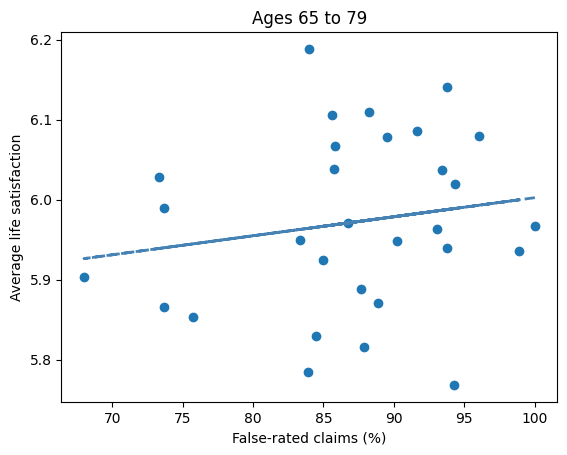

In [32]:
# ages 65 to 79

x = merged_data65to79["false_percentage"]
y = merged_data65to79["life_satisfaction_65to79"]

a, b = np.polyfit(x, y, 1)

plt.scatter(
    merged_data65to79["false_percentage"],
    merged_data65to79["life_satisfaction_65to79"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Ages 65 to 79")

plt.plot(x, a*x+b, color='steelblue', linestyle='--', linewidth=2)

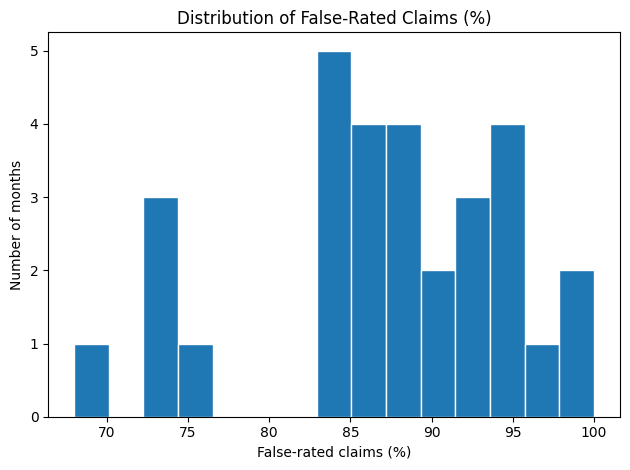

In [33]:
#Histogram of distribution of false rated claims for overall age

plt.hist(merged_data["false_percentage"], bins=15, edgecolor="white")
plt.title("Distribution of False-Rated Claims (%)")
plt.xlabel("False-rated claims (%)")
plt.ylabel("Number of months")
plt.tight_layout()

plt.show()

Comment: The distribution of false-rated claims is left-skewed, with most months having over 85% of checked claims rated false, suggesting that fact-checked claims are overwhelmingly false and limiting variation in this variable.

(Since the percentages of false rated claims are all mostly quite high, we can also question how the data is collected in real life. Maybe the fact checkers tend do prioritise checking more suspiciously sounding facts (???))

# Farah filters

In [34]:
urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1ljqNRhBubumE3G1X1-L7_s_f0ZGaTgYG", "life_satisfaction_4_year.xlsx")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=16877wjKTNJZn-NbAMn9bgLmTvl2BZAkB", "life_satisfaction_female.xlsx")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1ybAD4HUcTGk3OP7y6t9sMdKnIrtnFMA-", "life_satisfaction_male.xlsx")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1Ir1Sq54bCXrW1QO8uNxZxexDlwuZbJZl", "life_satisfaction_postgrad.xlsx")

('life_satisfaction_postgrad.xlsx',
 <http.client.HTTPMessage at 0x7f1154687750>)

In [35]:
life_satisfaction_4_year = pd.read_excel("life_satisfaction_4_year.xlsx")
life_satisfaction_postgrad = pd.read_excel("life_satisfaction_postgrad.xlsx")
life_satisfaction_female = pd.read_excel("life_satisfaction_female.xlsx")
life_satisfaction_male = pd.read_excel("life_satisfaction_male.xlsx")

### 4 years

In [36]:
# Filtered data 4 yr
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfaction4years = life_satisfaction_4_year.iloc[:11, 1:].T.copy()
satisfaction4years.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfaction4years[score] = (
        satisfaction4years[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentage4years = satisfaction4years.sum(axis=1)
weighted_total4years = 0

for score in range(11):
    weighted_total4years += score * satisfaction4years[score]

satisfaction4years["life_satisfaction_4_year"] = weighted_total4years / total_percentage4years


# Monthly life satisfaction

satisfaction4years["month"] = pd.to_datetime(
    satisfaction4years.index
).to_period("M")

life_monthly4years = satisfaction4years.groupby("month")["life_satisfaction_4_year"].agg(
    ["mean", "size"]
)

life_monthly4years.columns = ["life_satisfaction_4_year", "n_surveys"]
life_monthly4years = life_monthly4years.reset_index()


# Merge data

merged_data4years = pd.merge(
    politifact_monthly,
    life_monthly4years,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_data4years = merged_data4years[
    (merged_data4years["month"] >= "2023-10")
    & (merged_data4years["month"] <= "2026-03")
]

merged_data4years = merged_data4years.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_data4years))
print("Missing values:")
print(merged_data4years.isna().sum())

display(merged_data4years)

Number of months: 30
Missing values:
month                       0
n_checked                   0
false_percentage            0
life_satisfaction_4_year    0
n_surveys                   0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_4_year,n_surveys
0,2023-10,4,100.000000,6.535896,4
1,2023-11,50,84.000000,6.570361,5
2,2023-12,68,86.764706,6.609942,4
3,2024-01,119,88.235294,6.705532,4
4,2024-02,111,85.585586,6.699721,5
5,2024-03,155,85.806452,6.843112,4
6,2024-04,130,93.076923,6.692723,4
7,2024-05,133,90.225564,6.572447,5
8,2024-06,112,93.750000,6.673094,4
9,2024-07,143,91.608392,6.493900,4


Text(0.5, 1.0, '4 years of college')

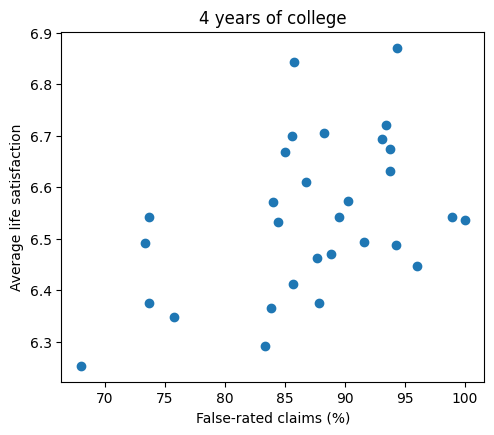

In [37]:
plt.figure(figsize=(12, 10))

plt.subplot(2,2,1)
plt.scatter(
    merged_data4years["false_percentage"],
    merged_data4years["life_satisfaction_4_year"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("4 years of college")

### Postgrad

In [38]:
# Filtered data 4 yr
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfactionpostgrad = life_satisfaction_postgrad.iloc[:11, 1:].T.copy()
satisfactionpostgrad.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfactionpostgrad[score] = (
        satisfactionpostgrad[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentagepostgrad = satisfactionpostgrad.sum(axis=1)
weighted_totalpostgrad = 0

for score in range(11):
    weighted_totalpostgrad += score * satisfactionpostgrad[score]

satisfactionpostgrad["life_satisfaction_postgrad"] = weighted_totalpostgrad / total_percentagepostgrad


# Monthly life satisfaction

satisfactionpostgrad["month"] = pd.to_datetime(
    satisfactionpostgrad.index
).to_period("M")

life_monthlypostgrad = satisfactionpostgrad.groupby("month")["life_satisfaction_postgrad"].agg(
    ["mean", "size"]
)

life_monthlypostgrad.columns = ["life_satisfaction_postgrad", "n_surveys"]
life_monthlypostgrad = life_monthlypostgrad.reset_index()


# Merge data

merged_datapostgrad = pd.merge(
    politifact_monthly,
    life_monthlypostgrad,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_datapostgrad = merged_datapostgrad[
    (merged_datapostgrad["month"] >= "2023-10")
    & (merged_datapostgrad["month"] <= "2026-03")
]

merged_datapostgrad = merged_datapostgrad.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_datapostgrad))
print("Missing values:")
print(merged_datapostgrad.isna().sum())

display(merged_datapostgrad)

Number of months: 30
Missing values:
month                         0
n_checked                     0
false_percentage              0
life_satisfaction_postgrad    0
n_surveys                     0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_postgrad,n_surveys
0,2023-10,4,100.000000,6.882189,4
1,2023-11,50,84.000000,6.975429,5
2,2023-12,68,86.764706,7.008720,4
3,2024-01,119,88.235294,6.959520,4
4,2024-02,111,85.585586,6.884477,5
5,2024-03,155,85.806452,6.971435,4
6,2024-04,130,93.076923,6.966515,4
7,2024-05,133,90.225564,6.904583,5
8,2024-06,112,93.750000,6.832089,4
9,2024-07,143,91.608392,6.933790,4


Text(0.5, 1.0, 'postgraduate education')

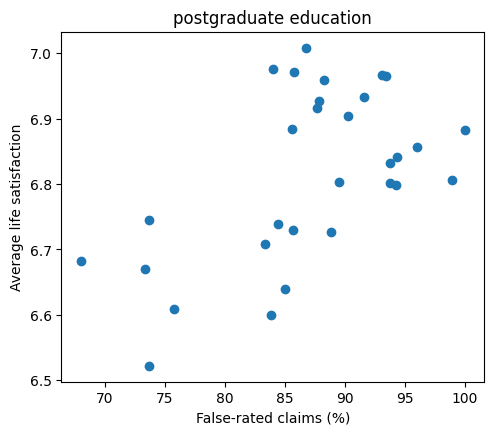

In [39]:
plt.figure(figsize=(12, 10))

plt.subplot(2,2,1)
plt.scatter(
    merged_datapostgrad["false_percentage"],
    merged_datapostgrad["life_satisfaction_postgrad"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("postgraduate education")

### female

In [40]:
# Filtered data 4 yr
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfactionfemale = life_satisfaction_female.iloc[:11, 1:].T.copy()
satisfactionfemale.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfactionfemale[score] = (
        satisfactionfemale[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentagefemale = satisfactionfemale.sum(axis=1)
weighted_totalfemale = 0

for score in range(11):
    weighted_totalfemale += score * satisfactionfemale[score]

satisfactionfemale["life_satisfaction_female"] = weighted_totalfemale / total_percentagefemale


# Monthly life satisfaction

satisfactionfemale["month"] = pd.to_datetime(
    satisfactionfemale.index
).to_period("M")

life_monthlyfemale = satisfactionfemale.groupby("month")["life_satisfaction_female"].agg(
    ["mean", "size"]
)

life_monthlyfemale.columns = ["life_satisfaction_female", "n_surveys"]
life_monthlyfemale = life_monthlyfemale.reset_index()


# Merge data

merged_datafemale = pd.merge(
    politifact_monthly,
    life_monthlyfemale,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_datafemale = merged_datafemale[
    (merged_datafemale["month"] >= "2023-10")
    & (merged_datafemale["month"] <= "2026-03")
]

merged_datafemale = merged_datafemale.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_datafemale))
print("Missing values:")
print(merged_datafemale.isna().sum())

display(merged_datafemale)

Number of months: 30
Missing values:
month                       0
n_checked                   0
false_percentage            0
life_satisfaction_female    0
n_surveys                   0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_female,n_surveys
0,2023-10,4,100.000000,6.253181,4
1,2023-11,50,84.000000,6.245111,5
2,2023-12,68,86.764706,6.252098,4
3,2024-01,119,88.235294,6.255333,4
4,2024-02,111,85.585586,6.347918,5
5,2024-03,155,85.806452,6.286687,4
6,2024-04,130,93.076923,6.258186,4
7,2024-05,133,90.225564,6.223293,5
8,2024-06,112,93.750000,6.211278,4
9,2024-07,143,91.608392,6.115775,4


Text(0.5, 1.0, 'Female')

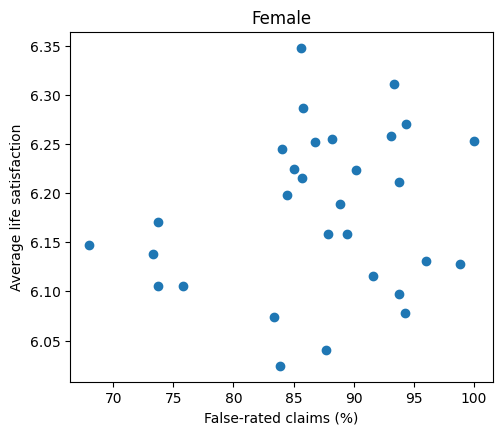

In [41]:
plt.figure(figsize=(12, 10))

plt.subplot(2,2,1)
plt.scatter(
    merged_datafemale["false_percentage"],
    merged_datafemale["life_satisfaction_female"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Female")

### male

In [42]:
# Filtered data 4 yr
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfactionmale = life_satisfaction_male.iloc[:11, 1:].T.copy()
satisfactionmale.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfactionmale[score] = (
        satisfactionmale[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentagemale = satisfactionmale.sum(axis=1)
weighted_totalmale = 0

for score in range(11):
    weighted_totalmale += score * satisfactionmale[score]

satisfactionmale["life_satisfaction_male"] = weighted_totalmale / total_percentagemale


# Monthly life satisfaction

satisfactionmale["month"] = pd.to_datetime(
    satisfactionmale.index
).to_period("M")

life_monthlymale = satisfactionmale.groupby("month")["life_satisfaction_male"].agg(
    ["mean", "size"]
)

life_monthlymale.columns = ["life_satisfaction_male", "n_surveys"]
life_monthlymale = life_monthlymale.reset_index()


# Merge data

merged_datamale = pd.merge(
    politifact_monthly,
    life_monthlymale,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_datamale = merged_datamale[
    (merged_datamale["month"] >= "2023-10")
    & (merged_datamale["month"] <= "2026-03")
]

merged_datamale = merged_datamale.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_datamale))
print("Missing values:")
print(merged_datamale.isna().sum())

display(merged_datamale)

Number of months: 30
Missing values:
month                     0
n_checked                 0
false_percentage          0
life_satisfaction_male    0
n_surveys                 0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_male,n_surveys
0,2023-10,4,100.000000,6.169518,4
1,2023-11,50,84.000000,6.240101,5
2,2023-12,68,86.764706,6.260826,4
3,2024-01,119,88.235294,6.340370,4
4,2024-02,111,85.585586,6.283505,5
5,2024-03,155,85.806452,6.362178,4
6,2024-04,130,93.076923,6.246831,4
7,2024-05,133,90.225564,6.302379,5
8,2024-06,112,93.750000,6.149402,4
9,2024-07,143,91.608392,6.207481,4


Text(0.5, 1.0, 'Male')

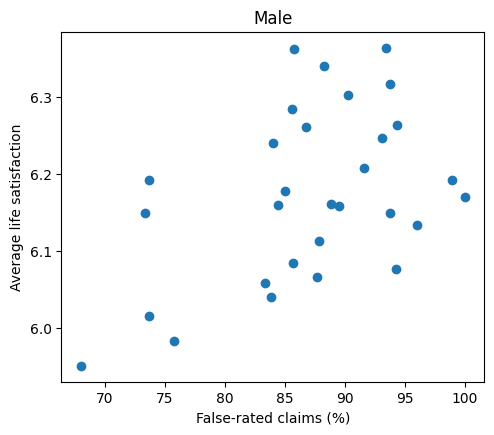

In [43]:
plt.figure(figsize=(12, 10))

plt.subplot(2,2,1)
plt.scatter(
    merged_datamale["false_percentage"],
    merged_datamale["life_satisfaction_male"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Male")

# Izzah


## Data loading and cleaning

In [44]:
# Loading the data

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=15fJqdsq2dbfYMvPYbluWk7mJ0laY1kr4", "life_satifaction_white.xlsx")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1JP2FXLtqVUjnmXLTEDohz0o02yiuqfe2", "life_satisfaction_black.xlsx")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1zXqqhFoTNUmO_R5uFqT-cPM-5MWpQnyy", "life_satisfaction_hispanic.xlsx")

urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=18OdsXKSuSzWTXNwPhknhXmAhjPMIA0vp", "life_satisfaction_asian.xlsx")


('life_satisfaction_asian.xlsx', <http.client.HTTPMessage at 0x7f11542f5450>)

In [45]:
# Reading them in

life_satisfaction_white = pd.read_excel("life_satifaction_white.xlsx")
life_satisfaction_black = pd.read_excel("life_satisfaction_black.xlsx")
life_satisfaction_hispanic = pd.read_excel("life_satisfaction_hispanic.xlsx")
life_satisfaction_asian = pd.read_excel("life_satisfaction_asian.xlsx")

In [46]:
life_satisfaction_white.isna().sum()
life_satisfaction_black.isna().sum()
life_satisfaction_hispanic.isna().sum()
life_satisfaction_asian.isna().sum()

,0
"Overall, how satisfied are you with your life nowadays?To be answered on a scale of 0 to 10, where 0 is “not at all” and 10 is “completely”.",0
2020-11-26 00:00:00,0
2020-12-03 00:00:00,0
2020-12-10 00:00:00,0
2020-12-17 00:00:00,0
...,...
2026-10-14 00:00:00,0
2026-10-21 00:00:00,0
2026-10-28 00:00:00,0
2026-11-04 00:00:00,0


## Data processing


In [47]:
# Filtered data by ethnicity processing
# Group: White
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfactionwhite = life_satisfaction_white.iloc[:11, 1:].T.copy()
satisfactionwhite.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfactionwhite[score] = (
        satisfactionwhite[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentagewhite = satisfactionwhite.sum(axis=1)
weighted_totalwhite = 0


for score in range(11):
    weighted_totalwhite += score * satisfactionwhite[score]

satisfactionwhite["life_satisfaction_white"] = weighted_totalwhite / total_percentagewhite


# Monthly life satisfaction

satisfactionwhite["month"] = pd.to_datetime(
    satisfactionwhite.index
).to_period("M")

life_monthlywhite = satisfactionwhite.groupby("month")["life_satisfaction_white"].agg(
    ["mean", "size"]
)

life_monthlywhite.columns = ["life_satisfaction_white", "n_surveys"]
life_monthlywhite = life_monthlywhite.reset_index()


# Merge data

merged_datawhite = pd.merge(
    politifact_monthly,
    life_monthlywhite,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_datawhite = merged_datawhite[
    (merged_datawhite["month"] >= "2023-10")
    & (merged_datawhite["month"] <= "2026-03")
]

merged_datawhite = merged_datawhite.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_datawhite))
print("Missing values:")
print(merged_datawhite.isna().sum())

display(merged_datawhite)

Number of months: 30
Missing values:
month                      0
n_checked                  0
false_percentage           0
life_satisfaction_white    0
n_surveys                  0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_white,n_surveys
0,2023-10,4,100.000000,6.290216,4
1,2023-11,50,84.000000,6.365483,5
2,2023-12,68,86.764706,6.320390,4
3,2024-01,119,88.235294,6.361335,4
4,2024-02,111,85.585586,6.355994,5
5,2024-03,155,85.806452,6.375206,4
6,2024-04,130,93.076923,6.300222,4
7,2024-05,133,90.225564,6.327316,5
8,2024-06,112,93.750000,6.265801,4
9,2024-07,143,91.608392,6.249201,4


In [48]:
# Filtered data ethnicity processing
# Group: Black
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfactionblack = life_satisfaction_black.iloc[:11, 1:].T.copy()
satisfactionblack.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfactionblack[score] = (
        satisfactionblack[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentageblack = satisfactionblack.sum(axis=1)
weighted_totalblack = 0


for score in range(11):
    weighted_totalblack += score * satisfactionblack[score]

satisfactionblack["life_satisfaction_black"] = weighted_totalblack / total_percentageblack


# Monthly life satisfaction

satisfactionblack["month"] = pd.to_datetime(
    satisfactionblack.index
).to_period("M")

life_monthlyblack = satisfactionblack.groupby("month")["life_satisfaction_black"].agg(
    ["mean", "size"]
)

life_monthlyblack.columns = ["life_satisfaction_black", "n_surveys"]
life_monthlyblack = life_monthlyblack.reset_index()


# Merge data

merged_datablack = pd.merge(
    politifact_monthly,
    life_monthlyblack,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_datablack = merged_datablack[
    (merged_datablack["month"] >= "2023-10")
    & (merged_datablack["month"] <= "2026-03")
]

merged_datablack = merged_datablack.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_datablack))
print("Missing values:")
print(merged_datablack.isna().sum())

display(merged_datablack)

Number of months: 30
Missing values:
month                      0
n_checked                  0
false_percentage           0
life_satisfaction_black    0
n_surveys                  0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_black,n_surveys
0,2023-10,4,100.000000,6.049962,4
1,2023-11,50,84.000000,6.198325,5
2,2023-12,68,86.764706,6.073260,4
3,2024-01,119,88.235294,6.234828,4
4,2024-02,111,85.585586,6.427491,5
5,2024-03,155,85.806452,6.336374,4
6,2024-04,130,93.076923,6.448214,4
7,2024-05,133,90.225564,6.040611,5
8,2024-06,112,93.750000,6.261351,4
9,2024-07,143,91.608392,6.169431,4


In [49]:
# Filtered data by ethnicity processing
# Group: Hispanic
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfactionhispanic = life_satisfaction_hispanic.iloc[:11, 1:].T.copy()
satisfactionhispanic.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfactionhispanic[score] = (
        satisfactionhispanic[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentagehispanic = satisfactionhispanic.sum(axis=1)
weighted_totalhispanic = 0


for score in range(11):
    weighted_totalhispanic += score * satisfactionhispanic[score]

satisfactionhispanic["life_satisfaction_hispanic"] = weighted_totalhispanic / total_percentagehispanic


# Monthly life satisfaction

satisfactionhispanic["month"] = pd.to_datetime(
    satisfactionhispanic.index
).to_period("M")

life_monthlyhispanic = satisfactionhispanic.groupby("month")["life_satisfaction_hispanic"].agg(
    ["mean", "size"]
)

life_monthlyhispanic.columns = ["life_satisfaction_hispanic", "n_surveys"]
life_monthlyhispanic = life_monthlyhispanic.reset_index()


# Merge data

merged_datahispanic = pd.merge(
    politifact_monthly,
    life_monthlyhispanic,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_datahispanic = merged_datahispanic[
    (merged_datahispanic["month"] >= "2023-10")
    & (merged_datahispanic["month"] <= "2026-03")
]

merged_datahispanic = merged_datahispanic.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_datahispanic))
print("Missing values:")
print(merged_datahispanic.isna().sum())

display(merged_datahispanic)

Number of months: 30
Missing values:
month                         0
n_checked                     0
false_percentage              0
life_satisfaction_hispanic    0
n_surveys                     0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_hispanic,n_surveys
0,2023-10,4,100.000000,6.319818,4
1,2023-11,50,84.000000,6.113279,5
2,2023-12,68,86.764706,6.284037,4
3,2024-01,119,88.235294,6.173047,4
4,2024-02,111,85.585586,6.236493,5
5,2024-03,155,85.806452,6.269930,4
6,2024-04,130,93.076923,6.096996,4
7,2024-05,133,90.225564,6.227607,5
8,2024-06,112,93.750000,6.037375,4
9,2024-07,143,91.608392,5.990551,4


In [50]:
# Filtered data by ethnicity processing
# Group: Asian
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfactionasian = life_satisfaction_asian.iloc[:11, 1:].T.copy()
satisfactionasian.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfactionasian[score] = (
        satisfactionasian[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentageasian = satisfactionasian.sum(axis=1)
weighted_totalasian = 0


for score in range(11):
    weighted_totalasian += score * satisfactionasian[score]

satisfactionasian["life_satisfaction_asian"] = weighted_totalasian / total_percentageasian


# Monthly life satisfaction

satisfactionasian["month"] = pd.to_datetime(
    satisfactionasian.index
).to_period("M")

life_monthlyasian = satisfactionasian.groupby("month")["life_satisfaction_asian"].agg(
    ["mean", "size"]
)

life_monthlyasian.columns = ["life_satisfaction_asian", "n_surveys"]
life_monthlyasian = life_monthlyasian.reset_index()


# Merge data

merged_dataasian = pd.merge(
    politifact_monthly,
    life_monthlyasian,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_dataasian = merged_dataasian[
    (merged_dataasian["month"] >= "2023-10")
    & (merged_dataasian["month"] <= "2026-03")
]

merged_dataasian = merged_dataasian.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_dataasian))
print("Missing values:")
print(merged_dataasian.isna().sum())

display(merged_dataasian)

Number of months: 30
Missing values:
month                      0
n_checked                  0
false_percentage           0
life_satisfaction_asian    0
n_surveys                  0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_asian,n_surveys
0,2023-10,4,100.000000,6.152039,4
1,2023-11,50,84.000000,5.977609,5
2,2023-12,68,86.764706,6.210064,4
3,2024-01,119,88.235294,6.267010,4
4,2024-02,111,85.585586,6.437155,5
5,2024-03,155,85.806452,6.490942,4
6,2024-04,130,93.076923,6.027020,4
7,2024-05,133,90.225564,6.123830,5
8,2024-06,112,93.750000,5.248189,4
9,2024-07,143,91.608392,5.559874,4


## Data visualisation



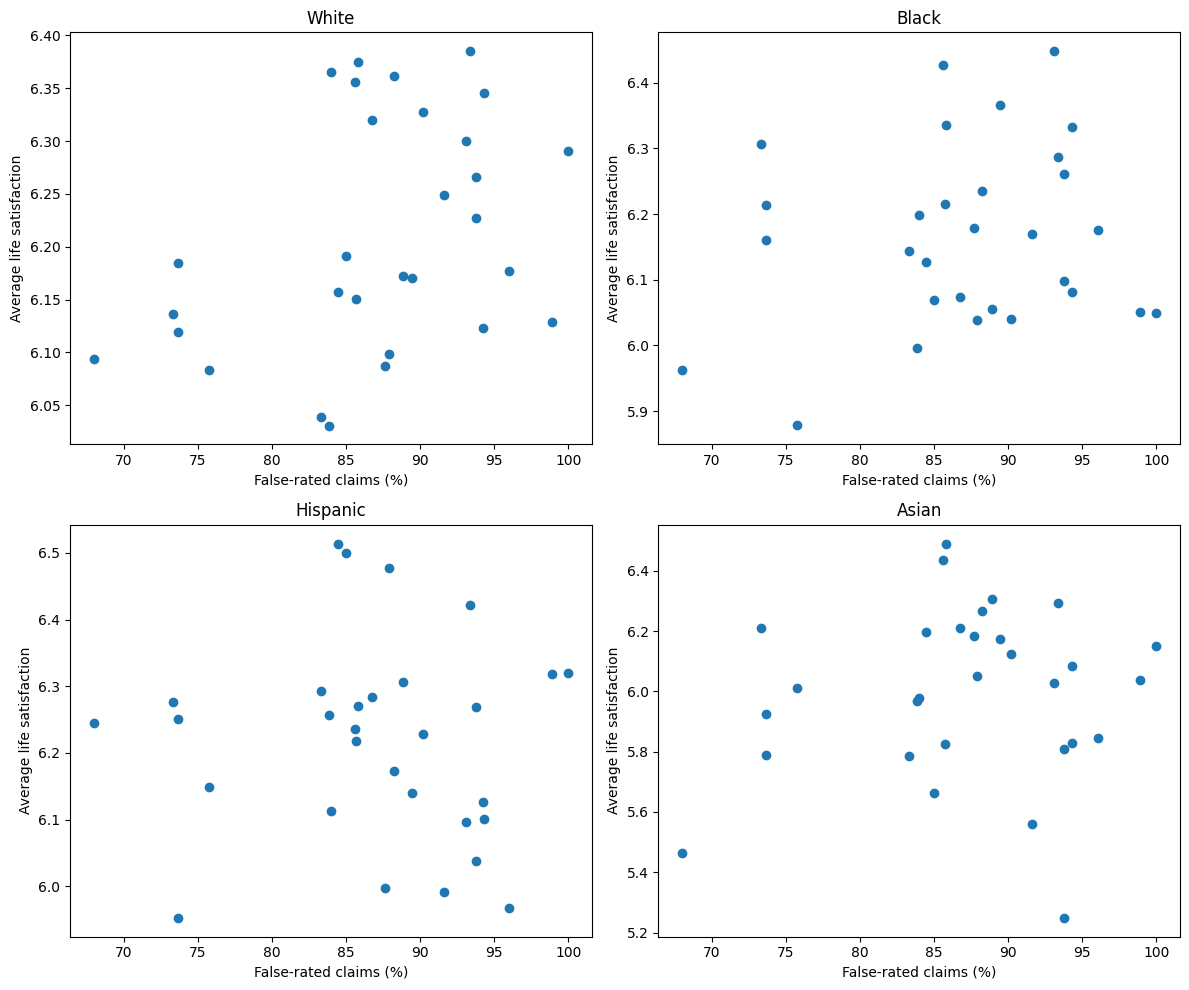

In [51]:
# Plots of life satisfaction against false-rated claims by ethnic groups

plt.figure(figsize=(12, 10))

plt.subplot(2,2,1)
plt.scatter(
    merged_datawhite["false_percentage"],
    merged_datawhite["life_satisfaction_white"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("White")



plt.subplot(2,2,2)
plt.scatter(
    merged_datablack["false_percentage"],
    merged_datablack["life_satisfaction_black"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Black")



plt.subplot(2,2,3)
plt.scatter(
    merged_datahispanic["false_percentage"],
    merged_datahispanic["life_satisfaction_hispanic"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Hispanic")



plt.subplot(2,2,4)
plt.scatter(
    merged_dataasian["false_percentage"],
    merged_dataasian["life_satisfaction_asian"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Asian")

plt.tight_layout()
plt.show()

## Yi

In [52]:
# importing all the datasets native american, middle eastern, 2 or more races & other
urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1Lv9RQdfMzJi4Q_ESBcGltAojSGhVbapv", "life_satisfaction_2ormore.xlsx")
urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1FzF8hxPqaPApU9DsHFWnDS_kacwQ3-mw", "life_satisfaction_middleeast.xlsx")
urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1phPduPF4txVECvUy4IWNQvEHSxIiGMk2", "life_satisfaction_nativeamerican.xlsx")
urllib.request.urlretrieve("https://drive.google.com/uc?export=download&id=1Ga4ofuk0-8XiUyjWFrz6nO2iOVEuaAF3", "life_satisfaction_other.xlsx")

('life_satisfaction_other.xlsx', <http.client.HTTPMessage at 0x7f11542f6030>)

In [53]:
# name the dataframes for the 4 demographic groups
life_satisfaction_2ormore = pd.read_excel("life_satisfaction_2ormore.xlsx")
life_satisfaction_middleeast = pd.read_excel("life_satisfaction_middleeast.xlsx")
life_satisfaction_nativeamerican = pd.read_excel("life_satisfaction_nativeamerican.xlsx")
life_satisfaction_other = pd.read_excel("life_satisfaction_other.xlsx")

Converting the data

In [54]:
# Filtered data by ethnicity
# 2ormore
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfaction2ormore = life_satisfaction_2ormore.iloc[:11, 1:].T.copy()
satisfaction2ormore.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfaction2ormore[score] = (
        satisfaction2ormore[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentage2ormore = satisfaction2ormore.sum(axis=1)
weighted_total2ormore = 0


for score in range(11):
    weighted_total2ormore += score * satisfaction2ormore[score]

satisfaction2ormore["life_satisfaction_2ormore"] = weighted_total2ormore / total_percentage2ormore


# Monthly life satisfaction

satisfaction2ormore["month"] = pd.to_datetime(
    satisfaction2ormore.index
).to_period("M")

life_monthly2ormore = satisfaction2ormore.groupby("month")["life_satisfaction_2ormore"].agg(
    ["mean", "size"]
)

life_monthly2ormore.columns = ["life_satisfaction_2ormore", "n_surveys"]
life_monthly2ormore = life_monthly2ormore.reset_index()


# Merge data

merged_data2ormore = pd.merge(
    politifact_monthly,
    life_monthly2ormore,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_data2ormore = merged_data2ormore[
    (merged_data2ormore["month"] >= "2023-10")
    & (merged_data2ormore["month"] <= "2026-03")
]

merged_data2ormore = merged_data2ormore.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_data2ormore))
print("Missing values:")
print(merged_data2ormore.isna().sum())

display(merged_data2ormore)

Number of months: 30
Missing values:
month                        0
n_checked                    0
false_percentage             0
life_satisfaction_2ormore    0
n_surveys                    0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_2ormore,n_surveys
0,2023-10,4,100.000000,4.962197,4
1,2023-11,50,84.000000,5.369349,5
2,2023-12,68,86.764706,5.490133,4
3,2024-01,119,88.235294,5.605855,4
4,2024-02,111,85.585586,5.383539,5
5,2024-03,155,85.806452,5.588411,4
6,2024-04,130,93.076923,5.419048,4
7,2024-05,133,90.225564,6.005711,5
8,2024-06,112,93.750000,5.465905,4
9,2024-07,143,91.608392,5.026146,4


In [55]:
# Filtered data by ethnicity
#  middleeast
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfactionmiddleeast = life_satisfaction_middleeast.iloc[:11, 1:].T.copy()
satisfactionmiddleeast.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfactionmiddleeast[score] = (
        satisfactionmiddleeast[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentagemiddleeast = satisfactionmiddleeast.sum(axis=1)
weighted_totalmiddleeast = 0


for score in range(11):
    weighted_totalmiddleeast += score * satisfactionmiddleeast[score]

satisfactionmiddleeast["life_satisfaction_middleeast"] = weighted_totalmiddleeast / total_percentagemiddleeast


# Monthly life satisfaction

satisfactionmiddleeast["month"] = pd.to_datetime(
    satisfactionmiddleeast.index
).to_period("M")

life_monthlymiddleeast = satisfactionmiddleeast.groupby("month")["life_satisfaction_middleeast"].agg(
    ["mean", "size"]
)

life_monthlymiddleeast.columns = ["life_satisfaction_middleeast", "n_surveys"]
life_monthlymiddleeast = life_monthlymiddleeast.reset_index()


# Merge data

merged_datamiddleeast = pd.merge(
    politifact_monthly,
    life_monthlymiddleeast,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_datamiddleeast = merged_datamiddleeast[
    (merged_datamiddleeast["month"] >= "2023-10")
    & (merged_datamiddleeast["month"] <= "2026-03")
]

merged_datamiddleeast = merged_datamiddleeast.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_datamiddleeast))
print("Missing values:")
print(merged_datamiddleeast.isna().sum())

display(merged_datamiddleeast)

Number of months: 30
Missing values:
month                           0
n_checked                       0
false_percentage                0
life_satisfaction_middleeast    0
n_surveys                       0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_middleeast,n_surveys
0,2023-10,4,100.000000,3.915000,4
1,2023-11,50,84.000000,5.977065,5
2,2023-12,68,86.764706,4.570724,3
3,2024-01,119,88.235294,5.306008,4
4,2024-02,111,85.585586,6.516667,5
5,2024-03,155,85.806452,5.675400,4
6,2024-04,130,93.076923,7.176016,4
7,2024-05,133,90.225564,6.094444,4
8,2024-06,112,93.750000,5.989820,3
9,2024-07,143,91.608392,5.653384,4


In [56]:
# Filtered data by ethnicity
# nativeamerican
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfactionnativeamerican = life_satisfaction_nativeamerican.iloc[:11, 1:].T.copy()
satisfactionnativeamerican.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfactionnativeamerican[score] = (
        satisfactionnativeamerican[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentagenativeamerican = satisfactionnativeamerican.sum(axis=1)
weighted_totalnativeamerican = 0


for score in range(11):
    weighted_totalnativeamerican += score * satisfactionnativeamerican[score]

satisfactionnativeamerican["life_satisfaction_nativeamerican"] = weighted_totalnativeamerican / total_percentagenativeamerican


# Monthly life satisfaction

satisfactionnativeamerican["month"] = pd.to_datetime(
    satisfactionnativeamerican.index
).to_period("M")

life_monthlynativeamerican = satisfactionnativeamerican.groupby("month")["life_satisfaction_nativeamerican"].agg(
    ["mean", "size"]
)

life_monthlynativeamerican.columns = ["life_satisfaction_nativeamerican", "n_surveys"]
life_monthlynativeamerican = life_monthlynativeamerican.reset_index()


# Merge data

merged_datanativeamerican = pd.merge(
    politifact_monthly,
    life_monthlynativeamerican,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_datanativeamerican = merged_datanativeamerican[
    (merged_datanativeamerican["month"] >= "2023-10")
    & (merged_datanativeamerican["month"] <= "2026-03")
]

merged_datanativeamerican = merged_datanativeamerican.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_datanativeamerican))
print("Missing values:")
print(merged_datanativeamerican.isna().sum())

display(merged_datanativeamerican)

Number of months: 30
Missing values:
month                               0
n_checked                           0
false_percentage                    0
life_satisfaction_nativeamerican    0
n_surveys                           0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_nativeamerican,n_surveys
0,2023-10,4,100.000000,6.094231,4
1,2023-11,50,84.000000,5.551010,5
2,2023-12,68,86.764706,5.511731,4
3,2024-01,119,88.235294,6.166400,4
4,2024-02,111,85.585586,5.950324,5
5,2024-03,155,85.806452,5.543334,4
6,2024-04,130,93.076923,7.166873,4
7,2024-05,133,90.225564,5.986429,5
8,2024-06,112,93.750000,6.018363,4
9,2024-07,143,91.608392,5.432400,4


In [57]:
# Filtered data by ethnicity
# other
# Average life satisfaction for each survey

# Select scores 0–10 and put dates in rows
satisfactionother = life_satisfaction_other.iloc[:11, 1:].T.copy()
satisfactionother.columns = range(11)

# Convert percentages to numbers
for score in range(11):
    satisfactionother[score] = (
        satisfactionother[score]*100
    )

# Calculate the average score, excluding "Don't know"
total_percentageother = satisfactionother.sum(axis=1)
weighted_totalother = 0


for score in range(11):
    weighted_totalother += score * satisfactionother[score]

satisfactionother["life_satisfaction_other"] = weighted_totalother / total_percentageother


# Monthly life satisfaction

satisfactionother["month"] = pd.to_datetime(
    satisfactionother.index
).to_period("M")

life_monthlyother = satisfactionother.groupby("month")["life_satisfaction_other"].agg(
    ["mean", "size"]
)

life_monthlyother.columns = ["life_satisfaction_other", "n_surveys"]
life_monthlyother = life_monthlyother.reset_index()


# Merge data

merged_dataother = pd.merge(
    politifact_monthly,
    life_monthlyother,
    on="month",
    how="inner",
    validate="one_to_one"
)

# Keep October 2023 to March 2026
merged_dataother = merged_dataother[
    (merged_dataother["month"] >= "2023-10")
    & (merged_dataother["month"] <= "2026-03")
]

merged_dataother = merged_dataother.sort_values("month").reset_index(drop=True)


# Check the result

print("Number of months:", len(merged_dataother))
print("Missing values:")
print(merged_dataother.isna().sum())

display(merged_dataother)

Number of months: 30
Missing values:
month                      0
n_checked                  0
false_percentage           0
life_satisfaction_other    0
n_surveys                  0
dtype: int64


,month,n_checked,false_percentage,life_satisfaction_other,n_surveys
0,2023-10,4,100.000000,5.800041,4
1,2023-11,50,84.000000,5.909756,5
2,2023-12,68,86.764706,6.323588,4
3,2024-01,119,88.235294,6.282559,4
4,2024-02,111,85.585586,6.158691,5
5,2024-03,155,85.806452,5.797590,4
6,2024-04,130,93.076923,6.010375,4
7,2024-05,133,90.225564,6.358172,5
8,2024-06,112,93.750000,6.489588,4
9,2024-07,143,91.608392,6.411365,4


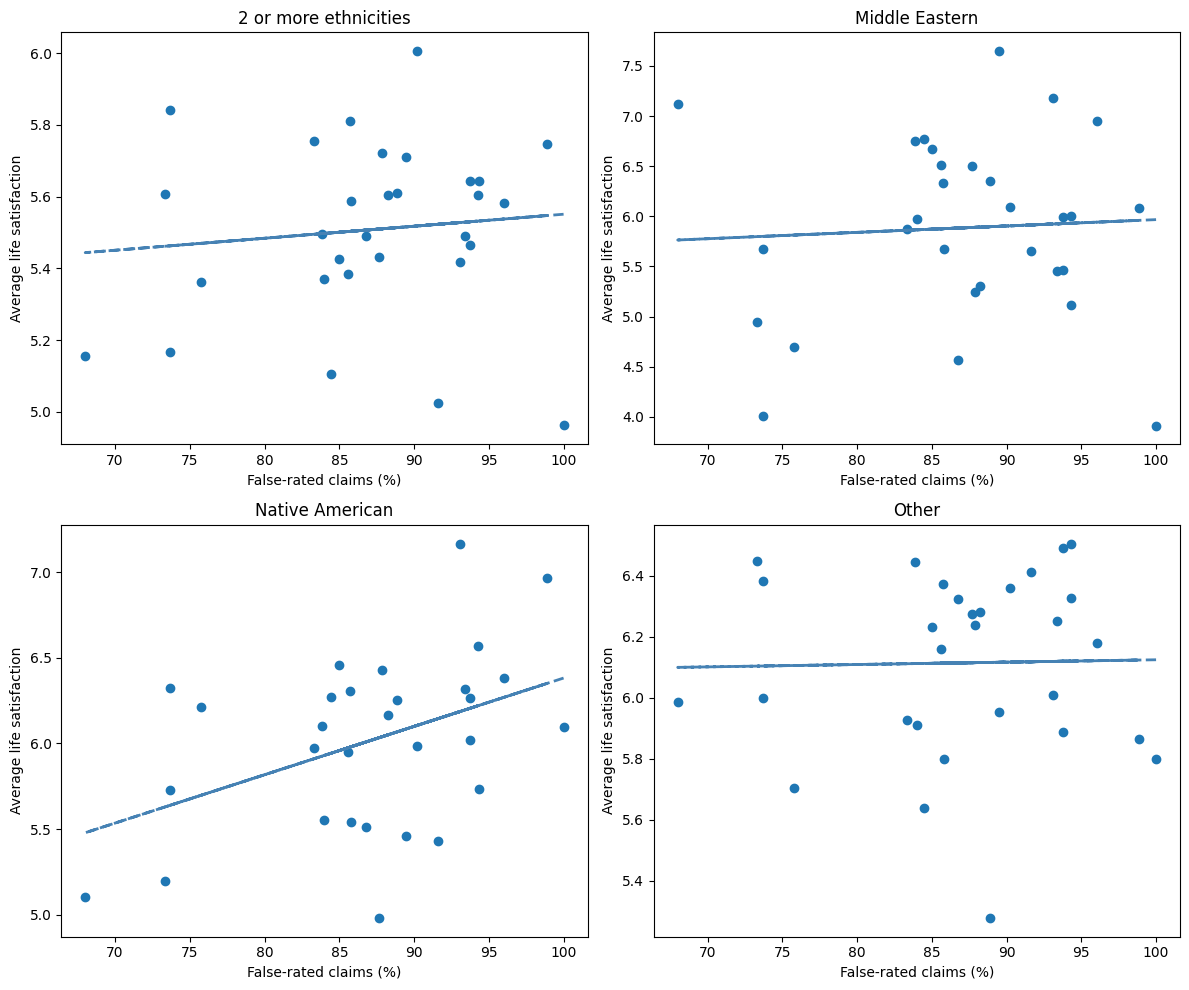

In [58]:
# Plot of life satisfaction against false-rated claims percentage by ethnicity
import matplotlib.pyplot as plt

# 2 or more ethnicities

plt.figure(figsize=(12, 10))

plt.subplot(2,2,1)
plt.scatter(
    merged_data2ormore["false_percentage"],
    merged_data2ormore["life_satisfaction_2ormore"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("2 or more ethnicities")

x = merged_data2ormore["false_percentage"]
y = merged_data2ormore["life_satisfaction_2ormore"]
a, b = np.polyfit(x, y, 1)
plt.plot(x, a*x+b, color='steelblue', linestyle='--', linewidth=2)


# Middle Eastern

plt.subplot(2,2,2)
plt.scatter(
    merged_datamiddleeast["false_percentage"],
    merged_datamiddleeast["life_satisfaction_middleeast"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Middle Eastern")

x = merged_datamiddleeast["false_percentage"]
y = merged_datamiddleeast["life_satisfaction_middleeast"]
a, b = np.polyfit(x, y, 1)
plt.plot(x, a*x+b, color='steelblue', linestyle='--', linewidth=2)


# Native American

plt.subplot(2,2,3)
plt.scatter(
    merged_datanativeamerican["false_percentage"],
    merged_datanativeamerican["life_satisfaction_nativeamerican"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Native American")
x = merged_datanativeamerican["false_percentage"]
y = merged_datanativeamerican["life_satisfaction_nativeamerican"]
a, b = np.polyfit(x, y, 1)
plt.plot(x, a*x+b, color='steelblue', linestyle='--', linewidth=2)


# Other

plt.subplot(2,2,4)
plt.scatter(
    merged_dataother["false_percentage"],
    merged_dataother["life_satisfaction_other"]
)

plt.xlabel("False-rated claims (%)")
plt.ylabel("Average life satisfaction")
plt.title("Other")
x = merged_dataother["false_percentage"]
y = merged_dataother["life_satisfaction_other"]
a, b = np.polyfit(x, y, 1)
plt.plot(x, a*x+b, color='steelblue', linestyle='--', linewidth=2)

plt.tight_layout()
plt.show()